In [1]:
import fastf1
import pandas as pd
import matplotlib.pyplot as plt
fastf1.Cache.enable_cache("../data/cache")

In [2]:
sessione = fastf1.get_session(2024, "Monza", "R")
sessione.load()

core           INFO 	Loading data for Italian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['16', '81', '4', '55', '44', '1', '63', '11', '23', '20', '14', '43', '3', '31', '10', '77', '27', '24', '18', '22']


In [3]:
giri = sessione.laps

In [4]:
ham = giri.pick_drivers("HAM").copy()
ham[["Compound", "TyreLife"]].head(53)

,Compound,TyreLife
212,MEDIUM,1.0
213,MEDIUM,2.0
214,MEDIUM,3.0
215,MEDIUM,4.0
216,MEDIUM,5.0
217,MEDIUM,6.0
218,MEDIUM,7.0
219,MEDIUM,8.0
220,MEDIUM,9.0
221,MEDIUM,10.0


In [5]:
ham["Compound"].value_counts()

Compound
HARD      38
MEDIUM    15
Name: count, dtype: int64

In [6]:
ham_filtered = ham[ham["Compound"] == "MEDIUM"]
ham_filtered

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
212,0 days 00:57:20.426000,HAM,44,0 days 00:01:29.674000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:30.629000,...,True,Mercedes,0 days 00:55:50.494000,2024-09-01 13:03:34.413,1,5.0,False,,False,False
213,0 days 00:58:46.469000,HAM,44,0 days 00:01:26.043000,2.0,1.0,NaT,NaT,0 days 00:00:27.701000,0 days 00:00:29.754000,...,True,Mercedes,0 days 00:57:20.426000,2024-09-01 13:05:04.345,1,5.0,False,,False,True
214,0 days 01:00:12.099000,HAM,44,0 days 00:01:25.630000,3.0,1.0,NaT,NaT,0 days 00:00:27.495000,0 days 00:00:29.688000,...,True,Mercedes,0 days 00:58:46.469000,2024-09-01 13:06:30.388,1,5.0,False,,False,True
215,0 days 01:01:37.821000,HAM,44,0 days 00:01:25.722000,4.0,1.0,NaT,NaT,0 days 00:00:27.650000,0 days 00:00:29.626000,...,True,Mercedes,0 days 01:00:12.099000,2024-09-01 13:07:56.018,1,5.0,False,,False,True
216,0 days 01:03:02.592000,HAM,44,0 days 00:01:24.771000,5.0,1.0,NaT,NaT,0 days 00:00:27.451000,0 days 00:00:29.134000,...,True,Mercedes,0 days 01:01:37.821000,2024-09-01 13:09:21.740,1,5.0,False,,False,True
217,0 days 01:04:27.511000,HAM,44,0 days 00:01:24.919000,6.0,1.0,NaT,NaT,0 days 00:00:27.565000,0 days 00:00:29.213000,...,True,Mercedes,0 days 01:03:02.592000,2024-09-01 13:10:46.511,1,5.0,False,,False,True
218,0 days 01:05:52.716000,HAM,44,0 days 00:01:25.205000,7.0,1.0,NaT,NaT,0 days 00:00:27.635000,0 days 00:00:29.267000,...,True,Mercedes,0 days 01:04:27.511000,2024-09-01 13:12:11.430,1,5.0,False,,False,True
219,0 days 01:07:17.587000,HAM,44,0 days 00:01:24.871000,8.0,1.0,NaT,NaT,0 days 00:00:27.605000,0 days 00:00:28.975000,...,True,Mercedes,0 days 01:05:52.716000,2024-09-01 13:13:36.635,1,5.0,False,,False,True
220,0 days 01:08:42.622000,HAM,44,0 days 00:01:25.035000,9.0,1.0,NaT,NaT,0 days 00:00:27.790000,0 days 00:00:29.067000,...,True,Mercedes,0 days 01:07:17.587000,2024-09-01 13:15:01.506,1,5.0,False,,False,True
221,0 days 01:10:07.531000,HAM,44,0 days 00:01:24.909000,10.0,1.0,NaT,NaT,0 days 00:00:27.537000,0 days 00:00:29.196000,...,True,Mercedes,0 days 01:08:42.622000,2024-09-01 13:16:26.541,1,5.0,False,,False,True


In [7]:
len(ham_filtered)

15

Avendo fatto 15 giri con le medie, dovrebbe aver girato il resto del gran premio con una/due mescole diverse. Dovrebbero mancare 38 giri (Potenzialmente Gomma Dura), se la gomma media è durata 15 giri, il pilota dovrebbe aver usato due set di gomma dura. Conferma cosi anche "TyreLife"

In [8]:
ham[["Compound", "Stint"]].head(53)

,Compound,Stint
212,MEDIUM,1.0
213,MEDIUM,1.0
214,MEDIUM,1.0
215,MEDIUM,1.0
216,MEDIUM,1.0
217,MEDIUM,1.0
218,MEDIUM,1.0
219,MEDIUM,1.0
220,MEDIUM,1.0
221,MEDIUM,1.0


In [9]:
ham.groupby(['Stint', 'Compound']).size()

Stint  Compound
1.0    MEDIUM      15
2.0    HARD        22
3.0    HARD        16
dtype: int64

In [10]:
sum_stints = ham.groupby(['Stint', 'Compound']).size().sum()
if (len(ham) == sum_stints):
    print("Tutti i giri sono avvenuti")
else:
    print("Non tutti i giri sono avvenuti")

Tutti i giri sono avvenuti


Controllando i valori forniti dallo stint e dal compound del driver avremmo che la mia ipotesi precedentemente formulata è stata ottimale grazie anche al controllo su TyreLife. 

In [11]:
lec = giri.pick_drivers("LEC").copy()
lec[["Compound", "TyreLife"]].head(53)
lec["Compound"].value_counts()

Compound
HARD      38
MEDIUM    15
Name: count, dtype: int64

In [12]:
sai = giri.pick_drivers("SAI")
sai[["Compound", "TyreLife"]].head(53)
sai["Compound"].value_counts()

Compound
HARD      34
MEDIUM    19
Name: count, dtype: int64

In [13]:
rus = giri.pick_drivers("RUS")
rus[["Compound", "TyreLife"]].head(53)
rus["Compound"].value_counts()

Compound
HARD      42
MEDIUM    11
Name: count, dtype: int64

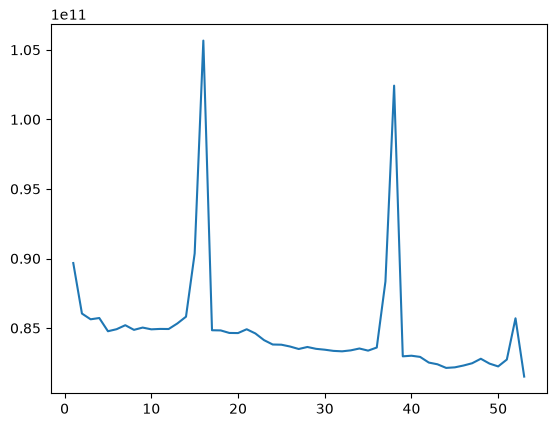

In [14]:
plt.plot(ham["LapNumber"], ham["LapTime"])
plt.show()

Dal grafico della sessione di gara di Hamilton notiamo come l'asse delle Y mostra un valore 1e11 (10^11) poiché FastF1 salva i tempi sui giri come Timedelta e quando si passano a Matplotlib senza convertirli si trasformano in nanosecondi. Notiamo inoltre due picchi e sicuramente saranno i due pit stop, siccome in pitlane la velocità deve essere contenuta i tempi di percorrimento in pista aumenta a dismisura. Sull'asse delle X avremo i giri percorsi nella gara.

In [15]:
ham["LapTimeSec"] = ham["LapTime"].dt.total_seconds()

In [16]:
ham["LapTimeSec"].head(53)


212     89.674
213     86.043
214     85.630
215     85.722
216     84.771
217     84.919
218     85.205
219     84.871
220     85.035
221     84.909
222     84.938
223     84.932
224     85.329
225     85.817
226     90.365
227    105.664
228     84.843
229     84.831
230     84.649
231     84.640
232     84.915
233     84.613
234     84.132
235     83.818
236     83.804
237     83.673
238     83.495
239     83.640
240     83.507
241     83.445
242     83.360
243     83.328
244     83.397
245     83.531
246     83.378
247     83.601
248     88.349
249    102.426
250     82.968
251     83.012
252     82.927
253     82.520
254     82.396
255     82.136
256     82.176
257     82.307
258     82.471
259     82.794
260     82.446
261     82.243
262     82.737
263     85.703
264     81.512
Name: LapTimeSec, dtype: float64

In [17]:
ham["LapTimeSec"].dtypes

dtype('float64')

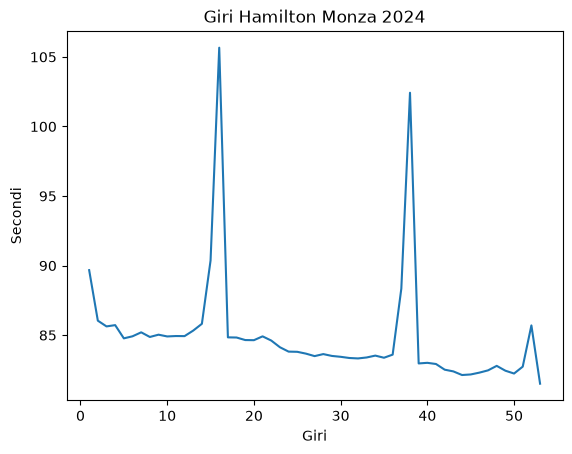

In [18]:
plt.plot(ham["LapNumber"], ham["LapTimeSec"])
plt.title("Giri Hamilton Monza 2024")
plt.xlabel("Giri")
plt.ylabel("Secondi")
plt.show()

Come si nota di nuovo, ci sono giri più lenti dovuti ai pitstop e anche al primo giro ovvero lo "Start Lap". Ora il grafico mostra i secondi invece dei nanosecondi nell'asse delle Y.

In [19]:
ham_IsAccurate = ham[ham["IsAccurate"]].copy()
ham_IsAccurate

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,LapTimeSec
213,0 days 00:58:46.469000,HAM,44,0 days 00:01:26.043000,2.0,1.0,NaT,NaT,0 days 00:00:27.701000,0 days 00:00:29.754000,...,Mercedes,0 days 00:57:20.426000,2024-09-01 13:05:04.345,1,5.0,False,,False,True,86.043
214,0 days 01:00:12.099000,HAM,44,0 days 00:01:25.630000,3.0,1.0,NaT,NaT,0 days 00:00:27.495000,0 days 00:00:29.688000,...,Mercedes,0 days 00:58:46.469000,2024-09-01 13:06:30.388,1,5.0,False,,False,True,85.630
215,0 days 01:01:37.821000,HAM,44,0 days 00:01:25.722000,4.0,1.0,NaT,NaT,0 days 00:00:27.650000,0 days 00:00:29.626000,...,Mercedes,0 days 01:00:12.099000,2024-09-01 13:07:56.018,1,5.0,False,,False,True,85.722
216,0 days 01:03:02.592000,HAM,44,0 days 00:01:24.771000,5.0,1.0,NaT,NaT,0 days 00:00:27.451000,0 days 00:00:29.134000,...,Mercedes,0 days 01:01:37.821000,2024-09-01 13:09:21.740,1,5.0,False,,False,True,84.771
217,0 days 01:04:27.511000,HAM,44,0 days 00:01:24.919000,6.0,1.0,NaT,NaT,0 days 00:00:27.565000,0 days 00:00:29.213000,...,Mercedes,0 days 01:03:02.592000,2024-09-01 13:10:46.511,1,5.0,False,,False,True,84.919
218,0 days 01:05:52.716000,HAM,44,0 days 00:01:25.205000,7.0,1.0,NaT,NaT,0 days 00:00:27.635000,0 days 00:00:29.267000,...,Mercedes,0 days 01:04:27.511000,2024-09-01 13:12:11.430,1,5.0,False,,False,True,85.205
219,0 days 01:07:17.587000,HAM,44,0 days 00:01:24.871000,8.0,1.0,NaT,NaT,0 days 00:00:27.605000,0 days 00:00:28.975000,...,Mercedes,0 days 01:05:52.716000,2024-09-01 13:13:36.635,1,5.0,False,,False,True,84.871
220,0 days 01:08:42.622000,HAM,44,0 days 00:01:25.035000,9.0,1.0,NaT,NaT,0 days 00:00:27.790000,0 days 00:00:29.067000,...,Mercedes,0 days 01:07:17.587000,2024-09-01 13:15:01.506,1,5.0,False,,False,True,85.035
221,0 days 01:10:07.531000,HAM,44,0 days 00:01:24.909000,10.0,1.0,NaT,NaT,0 days 00:00:27.537000,0 days 00:00:29.196000,...,Mercedes,0 days 01:08:42.622000,2024-09-01 13:16:26.541,1,5.0,False,,False,True,84.909
222,0 days 01:11:32.469000,HAM,44,0 days 00:01:24.938000,11.0,1.0,NaT,NaT,0 days 00:00:27.640000,0 days 00:00:29.078000,...,Mercedes,0 days 01:10:07.531000,2024-09-01 13:17:51.450,1,5.0,False,,False,True,84.938


In [20]:
len(ham_IsAccurate)

48

In [21]:
ham_IsAccurate["LapTimeSec"] = ham_IsAccurate["LapTime"].dt.total_seconds()

<function matplotlib.pyplot.show(close=None, block=None)>

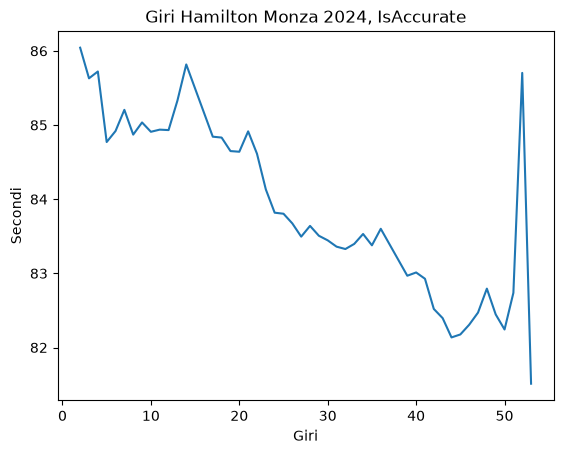

In [22]:
plt.plot(ham_IsAccurate["LapNumber"], ham_IsAccurate["LapTimeSec"])
plt.title("Giri Hamilton Monza 2024, IsAccurate")
plt.xlabel("Giri")
plt.ylabel("Secondi")
plt.show

Notiamo che in questo grafico, dove vengono mostrati solo i giri "Veloci", i secondi massimi all'interno del grafico si fermano a 85. Non vengono considerati i giri relativi al "Lap Start", entrata e uscita Pit-Stop.

In [23]:
lec_IsAccurate = lec[lec["IsAccurate"]].copy()
lec_IsAccurate["LapTimeSec"] = lec_IsAccurate["LapTime"].dt.total_seconds()

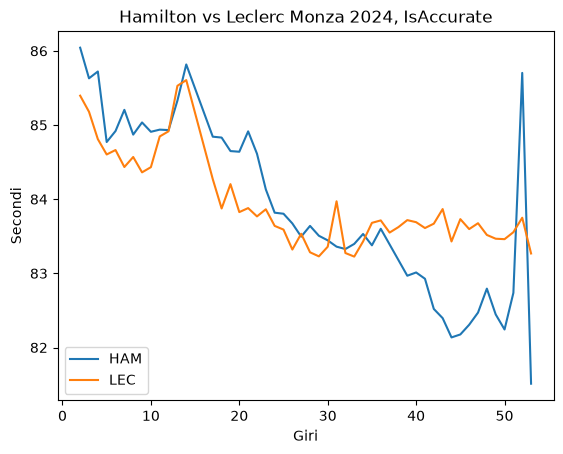

In [24]:
plt.plot(ham_IsAccurate["LapNumber"], ham_IsAccurate["LapTimeSec"], label="HAM")
plt.plot(lec_IsAccurate["LapNumber"], lec_IsAccurate["LapTimeSec"], label="LEC")
plt.title("Hamilton vs Leclerc Monza 2024, IsAccurate")
plt.xlabel("Giri")
plt.ylabel("Secondi")
plt.legend()
plt.show()